# Credit Default Prediction: PD Scorecard, Risk Grades & Expected Loss

**Data:** Lending Club consumer loans issued 2007–2011 (39,717 loans). The analysis keeps the 38,577 loans that had either been fully paid or charged off.

**Question:** Using only information available when a loan is approved, can we rank borrowers by default risk well enough to set risk grades? And does the interest rate charged in each grade cover the expected credit loss?

**Approach:**
1. Leakage-free features (nothing observed after origination)
2. **Out-of-time validation:** train on 2007–2010 loans, test on 2011 loans
3. A Weight-of-Evidence logistic scorecard (champion) vs. gradient boosting (challenger), benchmarked against Lending Club's own sub-grades
4. Points-based scorecard and six risk grades, with a population stability check
5. Loss given default and exposure at default measured from actual recoveries, then expected loss and loss-adjusted yield by grade

In [1]:
import os, urllib.request
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score, roc_curve, brier_score_loss

pd.set_option('display.float_format', lambda v: f'{v:,.3f}')
DATA = 'data/loan.csv'
URL = 'https://raw.githubusercontent.com/anushkaparadkar/lending-club-case-study/master/loan.csv'
if not os.path.exists(DATA):
    os.makedirs('data', exist_ok=True)
    urllib.request.urlretrieve(URL, DATA)   # public mirror of Lending Club 2007-2011 loan data (~35 MB)


raw = pd.read_csv(DATA, low_memory=False)
print(raw.shape)
raw.loan_status.value_counts()

(39717, 111)


loan_status
Fully Paid     32950
Charged Off     5627
Current         1140
Name: count, dtype: int64

## 1. Target and exclusions

- **Default = "Charged Off".** The 1,140 loans still current have no final outcome, so they are excluded.
- **Leakage control:** payment, recovery and last-activity fields are only known after origination. They are never used as model inputs, only later to measure loss.
- **Lending Club's own `grade`, `sub_grade` and `int_rate`** are excluded from the model and kept as a benchmark.

In [2]:
d = raw[raw.loan_status != 'Current'].copy()
d['default'] = (d.loan_status == 'Charged Off').astype(int)
d['issue'] = pd.to_datetime(d.issue_d, format='%b-%y')

POST_ORIGINATION = ['total_pymnt', 'total_pymnt_inv', 'total_rec_prncp', 'total_rec_int', 'total_rec_late_fee',
                    'recoveries', 'collection_recovery_fee', 'last_pymnt_d', 'last_pymnt_amnt', 'last_credit_pull_d',
                    'out_prncp', 'out_prncp_inv', 'next_pymnt_d']
print(f"Loans: {len(d):,} | default rate: {d.default.mean():.1%}")
d.groupby(d.issue.dt.year).default.agg(['size', 'mean']).rename(columns={'size': 'loans', 'mean': 'default rate'})

Loans: 38,577 | default rate: 14.6%


,loans,default rate
issue,,
2007,251,0.179
2008,1562,0.158
2009,4716,0.126
2010,11532,0.129
2011,20516,0.159


## 2. Feature engineering (application-time information only)

In [3]:
d['ecl'] = pd.to_datetime(d.earliest_cr_line, format='%b-%y')
d.loc[d.ecl > d.issue, 'ecl'] -= pd.DateOffset(years=100)          # fix 2-digit years such as 'Jan-62'
d['int_rate_n'] = d.int_rate.str.rstrip('%').astype(float) / 100      # benchmark only
d['revol_util_n'] = d.revol_util.str.rstrip('%').astype(float) / 100
d['term_60'] = (d.term.str.strip() == '60 months').astype(int)
d['emp_years'] = d.emp_length.replace({'< 1 year': '0', '10+ years': '10'}).str.extract(r'(\d+)')[0].astype(float)
d['credit_hist_yrs'] = (d.issue - d.ecl).dt.days / 365.25
d['log_income'] = np.log(d.annual_inc)
d['pti'] = d.installment / (d.annual_inc / 12)                         # payment-to-income
d['revol_to_income'] = d.revol_bal / d.annual_inc
d['loan_to_income'] = d.loan_amnt / d.annual_inc
d['any_pub_rec'] = (d.pub_rec > 0).astype(int)
d['any_delinq'] = (d.delinq_2yrs > 0).astype(int)
d['home'] = d.home_ownership.replace({'NONE': 'OTHER'})

NUM = ['loan_amnt', 'term_60', 'log_income', 'pti', 'loan_to_income', 'dti', 'revol_util_n', 'revol_to_income',
       'inq_last_6mths', 'open_acc', 'total_acc', 'credit_hist_yrs', 'emp_years', 'any_pub_rec', 'any_delinq']
CAT = ['home', 'verification_status', 'purpose']
assert not set(NUM + CAT) & set(POST_ORIGINATION)

train = d[d.issue.dt.year <= 2010].copy()   # development sample
test = d[d.issue.dt.year == 2011].copy()    # out-of-time validation
print(f"Train 2007-2010: {len(train):,} loans, default rate {train.default.mean():.1%}")
print(f"Test  2011:      {len(test):,} loans, default rate {test.default.mean():.1%}")

Train 2007-2010: 18,061 loans, default rate 13.1%
Test  2011:      20,516 loans, default rate 15.9%


## 3. Weight of Evidence and Information Value

Numeric features are split into six quantile bins on the training data. Each bin gets a Weight of Evidence, WoE = ln(% goods / % bads). Features with Information Value below 0.02 are dropped as weak.

In [4]:
def make_edges(x, q=6):
    if x.nunique() <= 6:
        return None
    e = np.unique(np.nanquantile(x, np.linspace(0, 1, q + 1)))
    e[0], e[-1] = -np.inf, np.inf
    return e

def binned(x, edges):
    if edges is None:
        return x.astype(str)
    return pd.cut(x, edges, include_lowest=True).astype(str).where(x.notna(), 'Missing')

EDGES, WOE, IV = {}, {}, {}
n_bad, n_good = train.default.sum(), (1 - train.default).sum()
for f in NUM + CAT:
    EDGES[f] = make_edges(train[f]) if f in NUM else None
    t = pd.crosstab(binned(train[f], EDGES[f]), train.default)
    pct_bad, pct_good = (t[1] + 0.5) / (n_bad + 0.5), (t[0] + 0.5) / (n_good + 0.5)
    WOE[f] = np.log(pct_good / pct_bad)
    IV[f] = ((pct_good - pct_bad) * WOE[f]).sum()

def to_woe(df, feats):
    return pd.DataFrame({f: binned(df[f], EDGES[f]).map(WOE[f]).fillna(0.0) for f in feats}, index=df.index)

iv = pd.Series(IV).sort_values(ascending=False).rename('Information Value').to_frame()
iv['kept'] = iv['Information Value'] >= 0.02
iv

,Information Value,kept
term_60,0.083,True
revol_util_n,0.071,True
purpose,0.070,True
loan_to_income,0.055,True
inq_last_6mths,0.045,True
pti,0.039,True
log_income,0.035,True
any_pub_rec,0.029,True
revol_to_income,0.021,True
emp_years,0.013,False


## 4. Champion model: WoE logistic regression

`loan_to_income` is dropped even though it passes the IV screen. It is highly correlated with payment-to-income, and keeping both gives it a coefficient with the wrong sign. In a scorecard, every coefficient should push the score the same direction as its feature's WoE.

In [5]:
FEATS = [f for f in iv.index[iv.kept] if f != 'loan_to_income']
Xtr, Xte = to_woe(train, FEATS), to_woe(test, FEATS)
lr = LogisticRegression(C=1.0, max_iter=2000).fit(Xtr, train.default)
train['pd'] = lr.predict_proba(Xtr)[:, 1]
test['pd'] = lr.predict_proba(Xte)[:, 1]
pd.Series(lr.coef_[0], index=FEATS, name='coefficient (all negative = consistent)').to_frame()

,coefficient (all negative = consistent)
term_60,-1.073
revol_util_n,-0.937
purpose,-1.026
inq_last_6mths,-1.066
pti,-0.808
log_income,-0.878
any_pub_rec,-0.940
revol_to_income,-0.423


## 5. Challenger: gradient boosting on raw features

In [6]:
Gtr, Gte = train[NUM + CAT].copy(), test[NUM + CAT].copy()
for c in CAT:
    cats = pd.Categorical(Gtr[c]).categories
    Gtr[c], Gte[c] = pd.Categorical(Gtr[c], categories=cats), pd.Categorical(Gte[c], categories=cats)
gbm = HistGradientBoostingClassifier(learning_rate=0.05, max_iter=400, max_leaf_nodes=15, min_samples_leaf=80,
                                     l2_regularization=1.0, early_stopping=True, validation_fraction=0.2,
                                     categorical_features='from_dtype', random_state=42).fit(Gtr, train.default)
test['pd_gbm'] = gbm.predict_proba(Gte)[:, 1]
print('boosting rounds kept by early stopping:', gbm.n_iter_)

boosting rounds kept by early stopping: 89


## 6. Out-of-time validation (2011 loans)

The benchmark is how well Lending Club's own sub-grade and interest rate rank the same loans. Lending Club's grades also used FICO scores, which this dataset does not include.

In [7]:
def ks(y, s):
    fpr, tpr, _ = roc_curve(y, s)
    return (tpr - fpr).max()

y = test.default
scores = {'Scorecard (WoE logistic)': test.pd, 'Gradient boosting': test.pd_gbm,
          'Lending Club sub-grade': test.sub_grade.rank(method='dense'), 'Lending Club interest rate': test.int_rate_n}
val = pd.DataFrame({k: {'AUC': roc_auc_score(y, s), 'Gini': 2 * roc_auc_score(y, s) - 1, 'KS': ks(y, s)}
                    for k, s in scores.items()}).T
val.loc['Scorecard (WoE logistic)', 'Brier'] = brier_score_loss(y, test.pd)
val.loc['Gradient boosting', 'Brier'] = brier_score_loss(y, test.pd_gbm)
both = LogisticRegression(max_iter=3000).fit(pd.concat([Xtr, train.sub_grade.rank(method='dense').rename('sg')], axis=1), train.default)
p_both = both.predict_proba(pd.concat([Xte, test.sub_grade.rank(method='dense').rename('sg')], axis=1))[:, 1]
val.loc['Scorecard + LC sub-grade', ['AUC', 'Gini', 'KS']] = [roc_auc_score(y, p_both), 2 * roc_auc_score(y, p_both) - 1, ks(y, p_both)]
print(f"Train AUC (scorecard): {roc_auc_score(train.default, train.pd):.3f}")
print(f"Mean predicted PD on 2011: {test.pd.mean():.1%} vs actual {y.mean():.1%}")
val

Train AUC (scorecard): 0.670
Mean predicted PD on 2011: 14.4% vs actual 15.9%


,AUC,Gini,KS,Brier
Scorecard (WoE logistic),0.701,0.402,0.305,0.124
Gradient boosting,0.701,0.401,0.301,0.125
Lending Club sub-grade,0.681,0.361,0.268,NaN
Lending Club interest rate,0.684,0.369,0.268,NaN
Scorecard + LC sub-grade,0.715,0.430,0.321,NaN


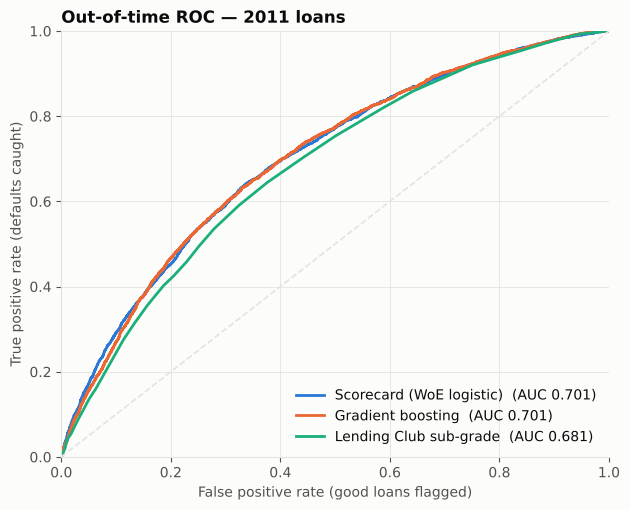

In [8]:
INK, INK2, GRID, SURF = '#0b0b0b', '#52514e', '#e4e3df', '#fcfcfb'
S1, S2, S3 = '#2a78d6', '#eb6834', '#1baf7a'
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 10, 'axes.edgecolor': GRID, 'axes.labelcolor': INK2,
                     'xtick.color': INK2, 'ytick.color': INK2, 'axes.titlecolor': INK, 'figure.facecolor': SURF,
                     'axes.facecolor': SURF, 'axes.spines.top': False, 'axes.spines.right': False})

fig, ax = plt.subplots(figsize=(6.4, 5.2))
for (name, s), col in zip([('Scorecard (WoE logistic)', test.pd), ('Gradient boosting', test.pd_gbm),
                           ('Lending Club sub-grade', scores['Lending Club sub-grade'])], [S1, S2, S3]):
    f, t, _ = roc_curve(y, s)
    ax.plot(f, t, color=col, lw=2, label=f"{name}  (AUC {roc_auc_score(y, s):.3f})")
ax.plot([0, 1], [0, 1], color=GRID, lw=1.2, ls='--')
ax.set(xlabel='False positive rate (good loans flagged)', ylabel='True positive rate (defaults caught)', xlim=(0, 1), ylim=(0, 1))
ax.set_title('Out-of-time ROC — 2011 loans', loc='left', fontweight='bold')
ax.grid(color=GRID, lw=0.6); ax.legend(frameon=False, loc='lower right', labelcolor=INK)
fig.tight_layout(); fig.savefig('roc_curve.png', dpi=150); plt.show()

## 7. Points-based scorecard

Scaling: **600 points = 50:1 odds (good:bad), and every 20 points doubles the odds.** Each feature bin contributes points, so a credit officer can see exactly why an applicant scored as they did.

In [9]:
PDO, BASE, BASE_ODDS = 20, 600, 50
factor = PDO / np.log(2)
offset = BASE - factor * np.log(BASE_ODDS)
b0, n = lr.intercept_[0], len(FEATS)

rows = []
for f, b in zip(FEATS, lr.coef_[0]):
    for bin_, w in WOE[f].items():
        rows.append({'feature': f, 'bin': bin_, 'WoE': w, 'points': round(offset / n + factor * (-(b * w) - b0 / n))})
card = pd.DataFrame(rows)
card.to_csv('scorecard_points.csv', index=False)

train['score'] = offset - factor * lr.decision_function(Xtr)
test['score'] = offset - factor * lr.decision_function(Xte)
check = card.set_index(['feature', 'bin']).points
pts = sum(binned(test[f], EDGES[f]).map(check.xs(f)).fillna(round(offset / n - factor * b0 / n)) for f in FEATS)
print('max |points total - model score|:', round(float((pts - test.score).abs().max()), 1), '(rounding only)')
card[card.feature.isin(['term_60', 'inq_last_6mths', 'revol_util_n'])]

max |points total - model score|: 2.7 (rounding only)


,feature,bin,WoE,points
0,term_60,0,0.149,72
1,term_60,1,-0.563,50
2,revol_util_n,"(-inf, 0.143]",0.373,78
3,revol_util_n,"(0.143, 0.311]",0.334,77
4,revol_util_n,"(0.311, 0.467]",0.022,68
5,revol_util_n,"(0.467, 0.624]",-0.037,67
6,revol_util_n,"(0.624, 0.798]",-0.161,63
7,revol_util_n,"(0.798, inf]",-0.368,58
8,revol_util_n,Missing,-1.031,40
23,inq_last_6mths,"(-inf, 1.0]",0.113,71


## 8. Risk grades and population stability

Six grades are set by score band. A useful grade system needs default rates that rise steadily from the best grade to the worst. The **Population Stability Index (PSI)** checks whether the 2011 applicant mix shifted from the development sample. Below 0.10 counts as stable.

In [10]:
CUTS = [-np.inf, 525, 535, 545, 555, 565, np.inf]
GRADES = ['RG6', 'RG5', 'RG4', 'RG3', 'RG2', 'RG1']          # RG1 = lowest risk
for df in (train, test):
    df['grade_rg'] = pd.cut(df.score, CUTS, labels=GRADES)

g = pd.DataFrame({
    'score band': ['565+', '555-565', '545-555', '535-545', '525-535', '<525'],
    'train share': train.grade_rg.value_counts(normalize=True).reindex(GRADES[::-1]).values,
    'test share': test.grade_rg.value_counts(normalize=True).reindex(GRADES[::-1]).values,
    'train default rate': train.groupby('grade_rg', observed=True).default.mean().reindex(GRADES[::-1]).values,
    'predicted PD (2011)': test.groupby('grade_rg', observed=True).pd.mean().reindex(GRADES[::-1]).values,
    'actual default rate (2011)': test.groupby('grade_rg', observed=True).default.mean().reindex(GRADES[::-1]).values,
}, index=GRADES[::-1])
g['PSI'] = (g['test share'] - g['train share']) * np.log(g['test share'] / g['train share'])
print(f"PSI = {g.PSI.sum():.3f}")
g

PSI = 0.027


,score band,train share,test share,train default rate,predicted PD (2011),actual default rate (2011),PSI
RG1,565+,0.130,0.113,0.042,0.052,0.042,0.002
RG2,555-565,0.177,0.156,0.078,0.075,0.074,0.003
RG3,545-555,0.226,0.213,0.105,0.102,0.109,0.001
RG4,535-545,0.205,0.191,0.142,0.137,0.149,0.001
RG5,525-535,0.136,0.146,0.182,0.184,0.218,0.001
RG6,<525,0.126,0.180,0.275,0.288,0.327,0.019


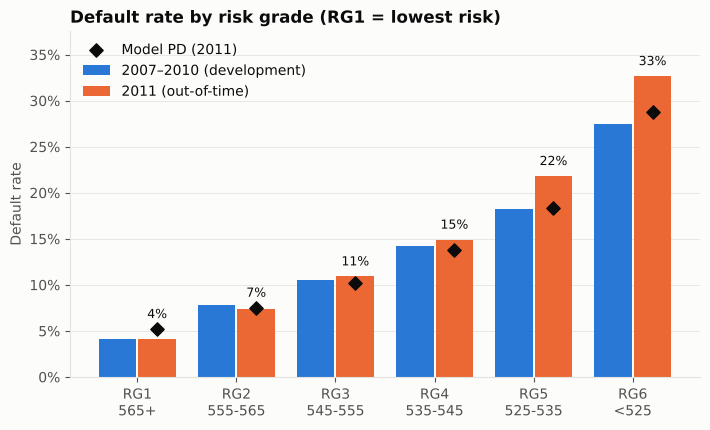

In [11]:
fig, ax = plt.subplots(figsize=(7.2, 4.4))
x = np.arange(len(GRADES)); w = 0.38
ax.bar(x - w/2 - 0.01, g['train default rate'], w, color=S1, label='2007–2010 (development)')
ax.bar(x + w/2 + 0.01, g['actual default rate (2011)'], w, color=S2, label='2011 (out-of-time)')
ax.scatter(x + w/2 + 0.01, g['predicted PD (2011)'], s=46, color=INK, zorder=3, marker='D', label='Model PD (2011)')
for i, (v, p) in enumerate(zip(g['actual default rate (2011)'], g['predicted PD (2011)'])):
    ax.text(i + w/2 + 0.01, max(v, p) + 0.012, f"{v:.0%}", ha='center', color=INK, fontsize=9)
ax.set_ylim(0, g['actual default rate (2011)'].max() * 1.15)
ax.set_xticks(x, [f"{gr}\n{b}" for gr, b in zip(g.index, g['score band'])])
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_ylabel('Default rate'); ax.grid(axis='y', color=GRID, lw=0.6); ax.set_axisbelow(True)
ax.set_title('Default rate by risk grade (RG1 = lowest risk)', loc='left', fontweight='bold')
ax.legend(frameon=False, labelcolor=INK)
fig.tight_layout(); fig.savefig('default_by_grade.png', dpi=150); plt.show()

## 9. Loss given default and exposure at default from actual recoveries

For each charged-off loan in the development sample:
- **EAD** = funded amount − principal repaid before default
- **Net recovery** = recoveries − collection fees
- **LGD** = 1 − net recovery / EAD

The severity factor converts a default into a loss as a share of the original loan.

In [12]:
co = train[train.default == 1]
ead = co.funded_amnt - co.total_rec_prncp
net_rec = co.recoveries - co.collection_recovery_fee
LGD = 1 - net_rec.sum() / ead.sum()
EAD_SHARE = ead.sum() / co.funded_amnt.sum()
SEVERITY = LGD * EAD_SHARE
print(f"Exposure at default: {EAD_SHARE:.1%} of the funded amount (borrowers repay some principal before defaulting)")
print(f"Loss given default:  {LGD:.1%} of EAD (dollar-weighted; net recoveries only {1 - LGD:.1%})")
print(f"Severity:            {SEVERITY:.1%} of the original loan is lost when a loan defaults")

Exposure at default: 63.8% of the funded amount (borrowers repay some principal before defaulting)
Loss given default:  93.1% of EAD (dollar-weighted; net recoveries only 6.9%)
Severity:            59.4% of the original loan is lost when a loan defaults


## 10. Expected loss vs. interest earned, by risk grade

- **Expected loss** (out-of-time) = model PD × severity.
- **Realized loss** = actual net charge-offs ÷ funded amount on 2011 loans.
- **Interest earned** = actual lifetime interest received ÷ funded amount.

All three are lifetime figures per $100 lent, before servicing costs and funding costs.

In [13]:
te = test.copy()
te['loss'] = np.where(te.default == 1, (te.funded_amnt - te.total_rec_prncp) - (te.recoveries - te.collection_recovery_fee), 0.0)
econ = te.groupby('grade_rg', observed=True).agg(loans=('default', 'size'), funded=('funded_amnt', 'sum'),
                                                 avg_rate=('int_rate_n', 'mean'), pd_model=('pd', 'mean'),
                                                 loss=('loss', 'sum'), interest=('total_rec_int', 'sum')).reindex(GRADES[::-1])
econ['expected loss'] = econ.pd_model * SEVERITY
econ['realized loss'] = econ.loss / econ.funded
econ['interest earned'] = econ.interest / econ.funded
econ['net yield after losses'] = econ['interest earned'] - econ['realized loss']
total = pd.Series({'loss': te.loss.sum() / te.funded_amnt.sum(), 'interest': te.total_rec_int.sum() / te.funded_amnt.sum()})
print(f"Portfolio (2011): realized loss {total.loss:.1%}, interest earned {total.interest:.1%}, net {total.interest - total.loss:.1%} of funded")
econ[['loans', 'avg_rate', 'pd_model', 'expected loss', 'realized loss', 'interest earned', 'net yield after losses']]

Portfolio (2011): realized loss 10.9%, interest earned 20.6%, net 9.7% of funded


,loans,avg_rate,pd_model,expected loss,realized loss,interest earned,net yield after losses
grade_rg,,,,,,,
RG1,2327,0.083,0.052,0.031,0.023,0.109,0.087
RG2,3198,0.097,0.075,0.045,0.032,0.135,0.103
RG3,4371,0.111,0.102,0.061,0.051,0.163,0.112
RG4,3925,0.123,0.137,0.082,0.082,0.200,0.119
RG5,3003,0.139,0.184,0.109,0.131,0.246,0.115
RG6,3692,0.158,0.288,0.171,0.229,0.285,0.056


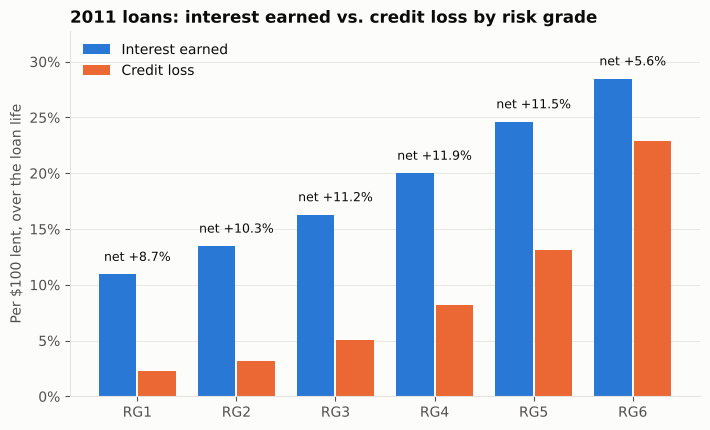

In [14]:
fig, ax = plt.subplots(figsize=(7.2, 4.4))
x = np.arange(len(GRADES)); w = 0.38
ax.bar(x - w/2 - 0.01, econ['interest earned'], w, color=S1, label='Interest earned')
ax.bar(x + w/2 + 0.01, econ['realized loss'], w, color=S2, label='Credit loss')
for i, (a, b) in enumerate(zip(econ['interest earned'], econ['net yield after losses'])):
    ax.text(i, a + 0.012, f"net {b:+.1%}", ha='center', color=INK, fontsize=9)
ax.set_ylim(0, econ['interest earned'].max() * 1.15)
ax.set_xticks(x, econ.index)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_ylabel('Per $100 lent, over the loan life'); ax.grid(axis='y', color=GRID, lw=0.6); ax.set_axisbelow(True)
ax.set_title('2011 loans: interest earned vs. credit loss by risk grade', loc='left', fontweight='bold')
ax.legend(frameon=False, labelcolor=INK, loc='upper left')
fig.tight_layout(); fig.savefig('loss_vs_interest.png', dpi=150); plt.show()

## 11. Conclusions

See the printed results above. The README summarizes the headline numbers.

1. **Ranking power.** The scorecard ranks 2011 defaults better than Lending Club's sub-grade, without FICO. Combining the two adds further lift, so the scorecard carries information the grade misses.
2. **Champion choice.** Gradient boosting gives no gain over the WoE scorecard. The scorecard is kept because it is transparent and every point can be explained to an applicant or a regulator.
3. **Calibration drift.** The applicant mix was stable (PSI well below 0.10), but default rates rose in 2011, especially in the riskiest grades. The model under-predicted, so PDs should be recalibrated to recent experience while the ranking is kept.
4. **Pricing.** Recoveries are very low (LGD about 93%). In the worst grade, credit losses take most of the interest earned, so those loans need higher pricing or tighter approval.

**Limitations:** no FICO or bureau attributes in the public data; loans still current were excluded; losses are measured before servicing and funding costs; a single lender and vintage period.